PyTorch version of `porter-delivery-time.ipynb`. The steps are the same as in the Keras (TensorFlow) notebook; only the neural network part is rewritten in PyTorch (model, training loop, loss plot and predictions). The data is downloaded from Google Drive with `!gdown` (as in the Keras notebook) and saved as `data_2.csv` in this folder, and the neural network is evaluated on the same test split as the random forest.

# **Porter Delivery time estimation**

Porter is India's Largest Marketplace for Intra-City Logistics. Leader in the country's $40 billion intra-city logistics market, Porter strives to improve the lives of 1,50,000+ driver-partners by providing them with consistent earning & independence. Currently, the company has serviced 5+ million customers

Porter works with a wide range of restaurants for delivering their items directly to the people.


**Problem statement**


Porter has a number of delivery partners available for delivering the food, from various restaurants and wants to get an estimated delivery time that it can provide the customers on the basis of what they are ordering, from where and also the delivery partners.

This dataset has the required data to train a regression model that will do the delivery time esimation, based on all those features

**Data Dictionary**

market_id : integer id for the market where the restaurant lies

created_at : the timestamp at which the order was placed

actual_delivery_time : the timestamp when the order was delivered

store_id	: encoded id for different stores

order_protocol	: integer code value for order protocol(how the order was placed ie: through porter, call to restaurant, prebooked, third part etc)

total_items	subtotal	: final price of the order

num_distinct_items	: the number of distinct items in the order

min_item_price	: price of the cheapest item in the order

max_item_price	: price of the costliest item in order

total_onshift_partners	: number of delivery partners on duty at the time order was placed

total_busy_partners	: number of delivery partners attending to other tasks

total_outstanding_orders	: total number of orders to be fulfilled at the moment

estimated_store_to_consumer_driving_duration : approximate travel time from restaurant to customer




**broad steps in the notebook**

*   load the data and understand the features
*   feature engineering creating target variable(time taken for each order)
*   cleaning the data and visualization
*   preparing the data for training
*   random forest regression
*   neural network regression
*   comarision of both ways





In [1]:
#for reading and handling the data
import pandas as pd
import numpy as np
import os
import random

#for visualizing and analyzing it
import matplotlib.pyplot as plt
import seaborn as sns

#data preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

#random forest model training
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import RandomForestRegressor

#Ann training (PyTorch)
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

#make the run repeatable
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: cpu


In [2]:
sns.set(rc={'figure.figsize':(11.7,8.27)})


LOading the data from google drive

In [3]:
!gdown 1WFa46c7_uSZ6GSzgYrDk4TKJd3y9zv8f

Using cookies from /Users/vinayakkumar.udikeri/.cache/gdown/cookies.txt


Downloading...
From: https://drive.google.com/uc?id=1WFa46c7_uSZ6GSzgYrDk4TKJd3y9zv8f
To: /Users/vinayakkumar.udikeri/Documents/Porter_NN_Regression/scaler_solution/data_2.csv
  0%|                                              | 0.00/15.7M [00:00<?, ?B/s]

  3%|█▎                                    | 524k/15.7M [00:00<00:04, 3.29MB/s]

 10%|███▋                                 | 1.57M/15.7M [00:00<00:02, 5.87MB/s]

 17%|██████▏                              | 2.62M/15.7M [00:00<00:02, 6.24MB/s]

 23%|████████▋                            | 3.67M/15.7M [00:00<00:01, 6.90MB/s]

... (8 outputs left out)

 83%|██████████████████████████████▊      | 13.1M/15.7M [00:01<00:00, 7.26MB/s]

 90%|█████████████████████████████████▎   | 14.2M/15.7M [00:02<00:00, 7.23MB/s]

 97%|███████████████████████████████████▊ | 15.2M/15.7M [00:02<00:00, 7.27MB/s]

100%|█████████████████████████████████████| 15.7M/15.7M [00:02<00:00, 7.03MB/s]


In [4]:
df=pd.read_csv('data_2.csv')
df.head()

,market_id,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_store_to_consumer_driving_duration
0,1.0,2015-02-06 22:24:17,2015-02-06 23:11:17,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,861.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:33:25,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,690.0
2,2.0,2015-02-16 00:11:35,2015-02-16 01:06:35,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,289.0
3,1.0,2015-02-12 03:36:46,2015-02-12 04:35:46,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,795.0
4,1.0,2015-01-27 02:12:36,2015-01-27 02:58:36,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,205.0


Printing the information and head of the data to get an understanding of it

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   market_id                                     175777 non-null  float64
 1   created_at                                    175777 non-null  str    
 2   actual_delivery_time                          175777 non-null  str    
 3   store_primary_category                        175777 non-null  int64  
 4   order_protocol                                175777 non-null  float64
 5   total_items                                   175777 non-null  int64  
 6   subtotal                                      175777 non-null  int64  
 7   num_distinct_items                            175777 non-null  int64  
 8   min_item_price                                175777 non-null  int64  
 9   max_item_price                                175777 non-nu

# Data preprocessing

## Feature engineering
we have the time at which the order was placed and time at which it was delivired, so we will create a new column for time taken in delivery and that will be our target column

calculating time taken in delivery by subtracting the order timestamp from delivery timestamp


the time stamos that we have now are in object format and need to be convertd to datetime format for easily working with them as intended.
the pandas datetime function checks if the data is in correct format for it and also understands the order of the data and converts accordingly

In [6]:
df['created_at']= pd.to_datetime(df['created_at'])
df['actual_delivery_time']= pd.to_datetime(df['actual_delivery_time'])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype         
---  ------                                        --------------   -----         
 0   market_id                                     175777 non-null  float64       
 1   created_at                                    175777 non-null  datetime64[us]
 2   actual_delivery_time                          175777 non-null  datetime64[us]
 3   store_primary_category                        175777 non-null  int64         
 4   order_protocol                                175777 non-null  float64       
 5   total_items                                   175777 non-null  int64         
 6   subtotal                                      175777 non-null  int64         
 7   num_distinct_items                            175777 non-null  int64         
 8   min_item_price                                175777 non-null  in

In [7]:
df['time_taken']=df['actual_delivery_time']-df['created_at']
df.head()

,market_id,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_store_to_consumer_driving_duration,time_taken
0,1.0,2015-02-06 22:24:17,2015-02-06 23:11:17,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,861.0,0 days 00:47:00
1,2.0,2015-02-10 21:49:25,2015-02-10 22:33:25,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,690.0,0 days 00:44:00
2,2.0,2015-02-16 00:11:35,2015-02-16 01:06:35,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,289.0,0 days 00:55:00
3,1.0,2015-02-12 03:36:46,2015-02-12 04:35:46,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,795.0,0 days 00:59:00
4,1.0,2015-01-27 02:12:36,2015-01-27 02:58:36,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,205.0,0 days 00:46:00


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 15 columns):
 #   Column                                        Non-Null Count   Dtype          
---  ------                                        --------------   -----          
 0   market_id                                     175777 non-null  float64        
 1   created_at                                    175777 non-null  datetime64[us] 
 2   actual_delivery_time                          175777 non-null  datetime64[us] 
 3   store_primary_category                        175777 non-null  int64          
 4   order_protocol                                175777 non-null  float64        
 5   total_items                                   175777 non-null  int64          
 6   subtotal                                      175777 non-null  int64          
 7   num_distinct_items                            175777 non-null  int64          
 8   min_item_price                                175777 no

now that we have our time taken for the delivery we can convert it to minutes and that will be our target variable to train the models

the timedelta is a datatype that stores the time difference and it is better we convert it to float and converting to minute does that as well

In [9]:
df['time_taken_mins']=pd.to_timedelta(df['time_taken'])/pd.Timedelta('60s')
df.head()

,market_id,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_store_to_consumer_driving_duration,time_taken,time_taken_mins
0,1.0,2015-02-06 22:24:17,2015-02-06 23:11:17,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,861.0,0 days 00:47:00,47.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:33:25,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,690.0,0 days 00:44:00,44.0
2,2.0,2015-02-16 00:11:35,2015-02-16 01:06:35,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,289.0,0 days 00:55:00,55.0
3,1.0,2015-02-12 03:36:46,2015-02-12 04:35:46,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,795.0,0 days 00:59:00,59.0
4,1.0,2015-01-27 02:12:36,2015-01-27 02:58:36,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,205.0,0 days 00:46:00,46.0


we can also extract the hour at which the order was places and which day of week it was

In [10]:
df['hour'] = df['created_at'].dt.hour

df['day'] = df['created_at'].dt.dayofweek

df.head()

/var/folders/bn/brz4gkd56s9c6wyvdx2510gm0000gq/T/ipykernel_39429/2326641192.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['day'] = df['created_at'].dt.dayofweek


,market_id,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_store_to_consumer_driving_duration,time_taken,time_taken_mins,hour,day
0,1.0,2015-02-06 22:24:17,2015-02-06 23:11:17,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,861.0,0 days 00:47:00,47.0,22,4
1,2.0,2015-02-10 21:49:25,2015-02-10 22:33:25,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,690.0,0 days 00:44:00,44.0,21,1
2,2.0,2015-02-16 00:11:35,2015-02-16 01:06:35,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,289.0,0 days 00:55:00,55.0,0,0
3,1.0,2015-02-12 03:36:46,2015-02-12 04:35:46,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,795.0,0 days 00:59:00,59.0,3,3
4,1.0,2015-01-27 02:12:36,2015-01-27 02:58:36,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,205.0,0 days 00:46:00,46.0,2,1


Dropping the columns that are no longer required

In [11]:
df.drop(['time_taken','created_at','actual_delivery_time'],axis=1,inplace=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 15 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   market_id                                     175777 non-null  float64
 1   store_primary_category                        175777 non-null  int64  
 2   order_protocol                                175777 non-null  float64
 3   total_items                                   175777 non-null  int64  
 4   subtotal                                      175777 non-null  int64  
 5   num_distinct_items                            175777 non-null  int64  
 6   min_item_price                                175777 non-null  int64  
 7   max_item_price                                175777 non-null  int64  
 8   total_onshift_dashers                         175777 non-null  float64
 9   total_busy_dashers                            175777 non-nu

/var/folders/bn/brz4gkd56s9c6wyvdx2510gm0000gq/T/ipykernel_39429/1377008954.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['time_taken','created_at','actual_delivery_time'],axis=1,inplace=True)


Checking null values in the data

In [12]:
df.isna().sum()

market_id                                       0
store_primary_category                          0
order_protocol                                  0
total_items                                     0
subtotal                                        0
num_distinct_items                              0
min_item_price                                  0
max_item_price                                  0
total_onshift_dashers                           0
total_busy_dashers                              0
total_outstanding_orders                        0
estimated_store_to_consumer_driving_duration    0
time_taken_mins                                 0
hour                                            0
day                                             0
dtype: int64

dropping null values from the data

In [13]:
df.dropna(inplace=True)
print(df.shape)

(175777, 15)


/var/folders/bn/brz4gkd56s9c6wyvdx2510gm0000gq/T/ipykernel_39429/1557188890.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


Plotting correlation to get an idea of the data

<Axes: >

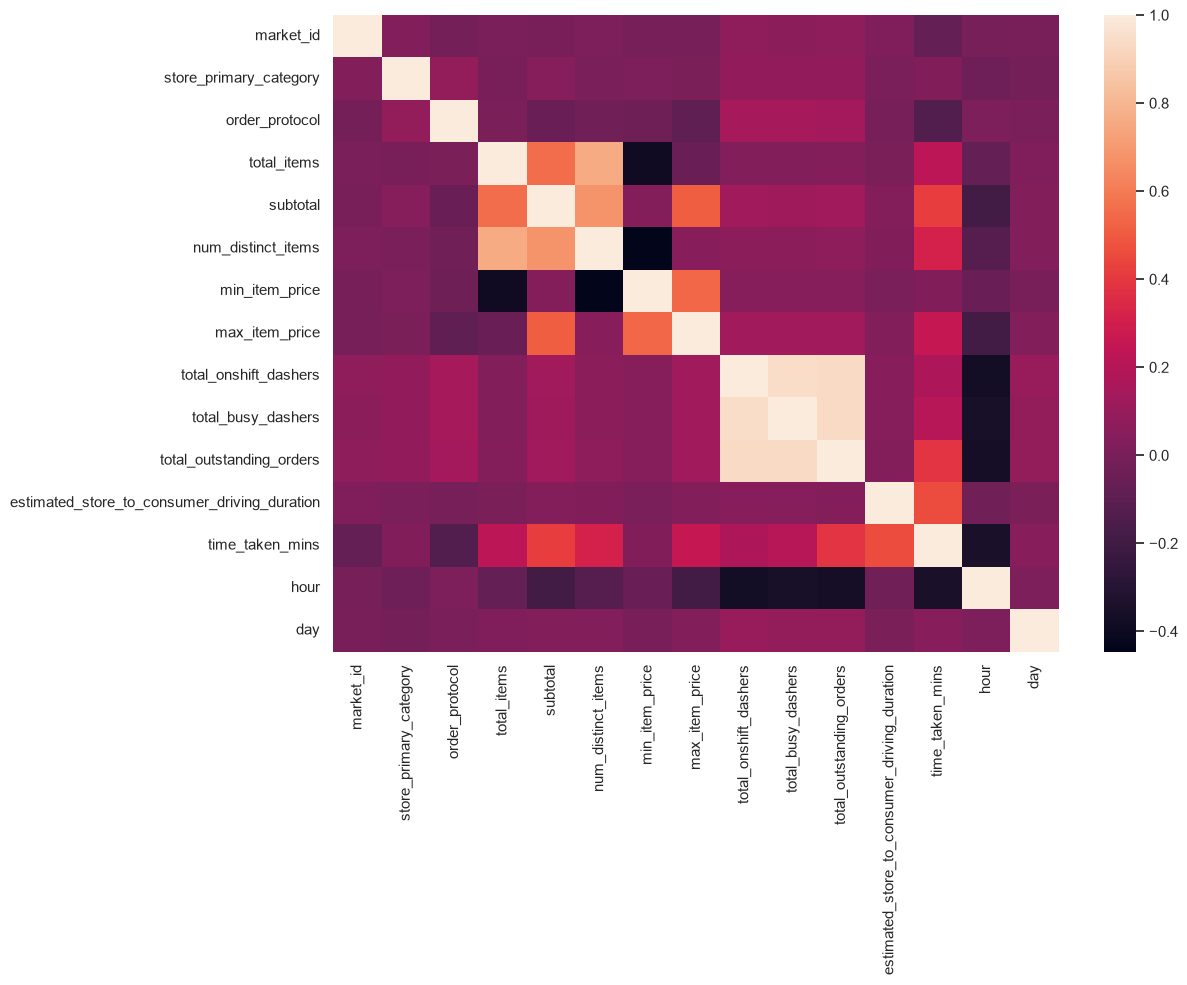

In [14]:
sns.heatmap(df.corr())

we have one categoriacal column which we will change to integer for model

In [15]:
df['store_primary_category'] = df['store_primary_category'].astype('category').cat.codes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 15 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   market_id                                     175777 non-null  float64
 1   store_primary_category                        175777 non-null  int8   
 2   order_protocol                                175777 non-null  float64
 3   total_items                                   175777 non-null  int64  
 4   subtotal                                      175777 non-null  int64  
 5   num_distinct_items                            175777 non-null  int64  
 6   min_item_price                                175777 non-null  int64  
 7   max_item_price                                175777 non-null  int64  
 8   total_onshift_dashers                         175777 non-null  float64
 9   total_busy_dashers                            175777 non-nu

## Data visualization and cleaning

<Axes: xlabel='time_taken_mins', ylabel='subtotal'>

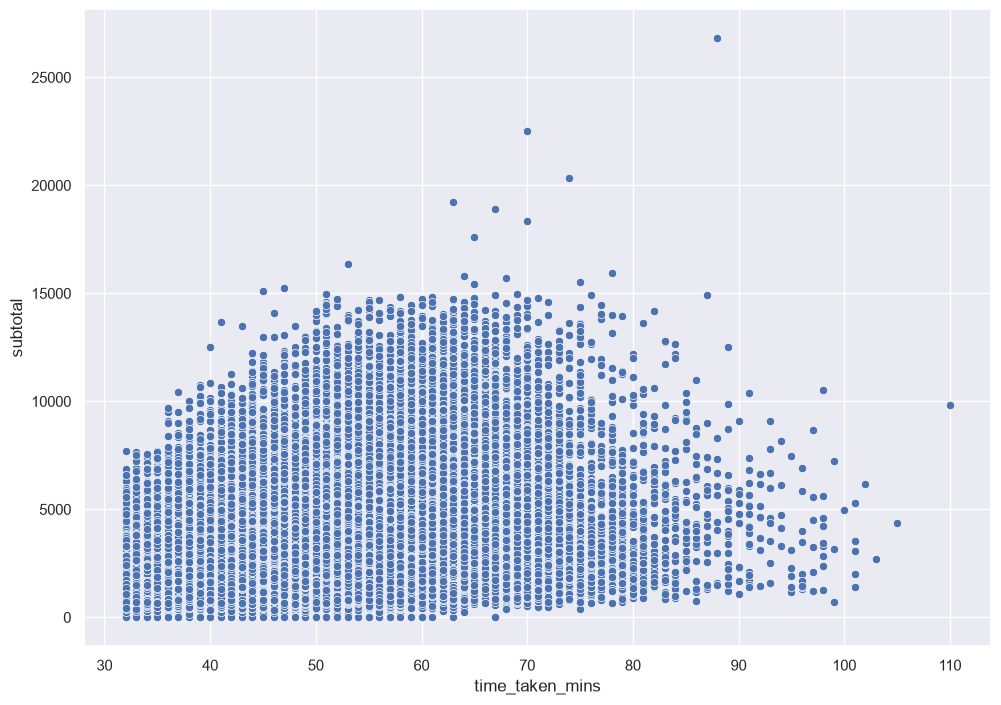

In [16]:
sns.scatterplot(x='time_taken_mins', y='subtotal', data=df)

<Axes: xlabel='total_items', ylabel='subtotal'>

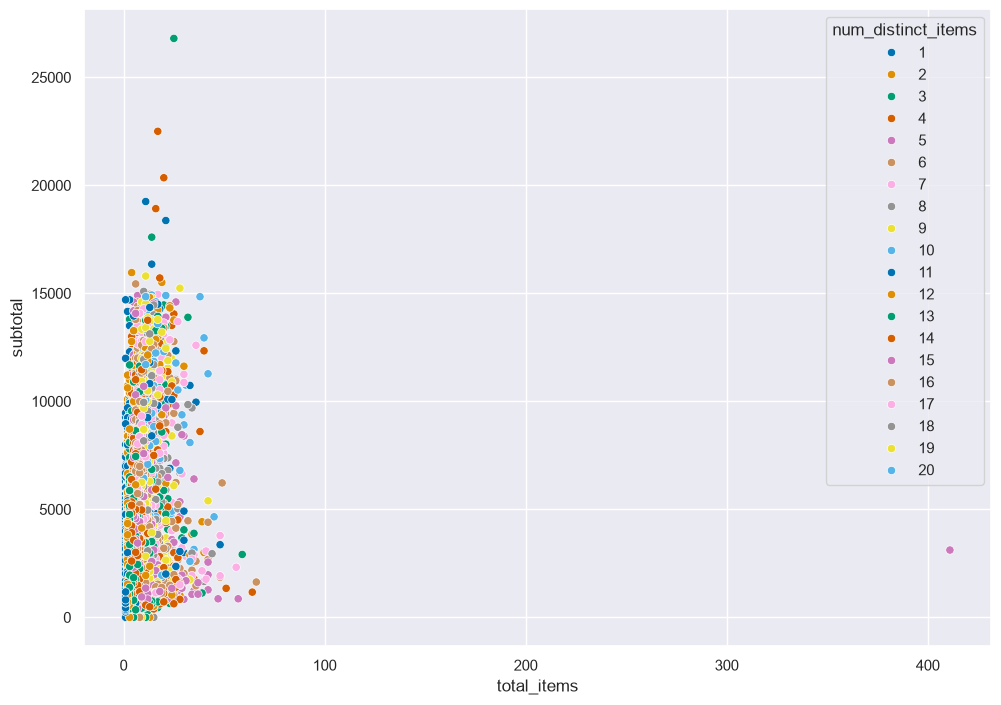

In [17]:
sns.scatterplot(x='total_items', y='subtotal', hue='num_distinct_items',palette='colorblind', data=df)

In [18]:
from sklearn.neighbors import LocalOutlierFactor
import matplotlib.pyplot as plt
model1 = LocalOutlierFactor(n_jobs=-1)
#model1.fit(df)
df['lof_anomaly_score'] = model1.fit_predict(df)


In [19]:
print("number of outliers : ",(len(df.loc[(df['lof_anomaly_score'] == -1)])))
df=df.loc[(df['lof_anomaly_score'] == 1)]


number of outliers :  831


In [20]:
df.drop(['lof_anomaly_score'],axis=1,inplace=True)

df.info()

<class 'pandas.DataFrame'>
Index: 174946 entries, 0 to 175776
Data columns (total 15 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   market_id                                     174946 non-null  float64
 1   store_primary_category                        174946 non-null  int8   
 2   order_protocol                                174946 non-null  float64
 3   total_items                                   174946 non-null  int64  
 4   subtotal                                      174946 non-null  int64  
 5   num_distinct_items                            174946 non-null  int64  
 6   min_item_price                                174946 non-null  int64  
 7   max_item_price                                174946 non-null  int64  
 8   total_onshift_dashers                         174946 non-null  float64
 9   total_busy_dashers                            174946 non-null  f

/var/folders/bn/brz4gkd56s9c6wyvdx2510gm0000gq/T/ipykernel_39429/2113450411.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['lof_anomaly_score'],axis=1,inplace=True)


<Axes: xlabel='time_taken_mins', ylabel='subtotal'>

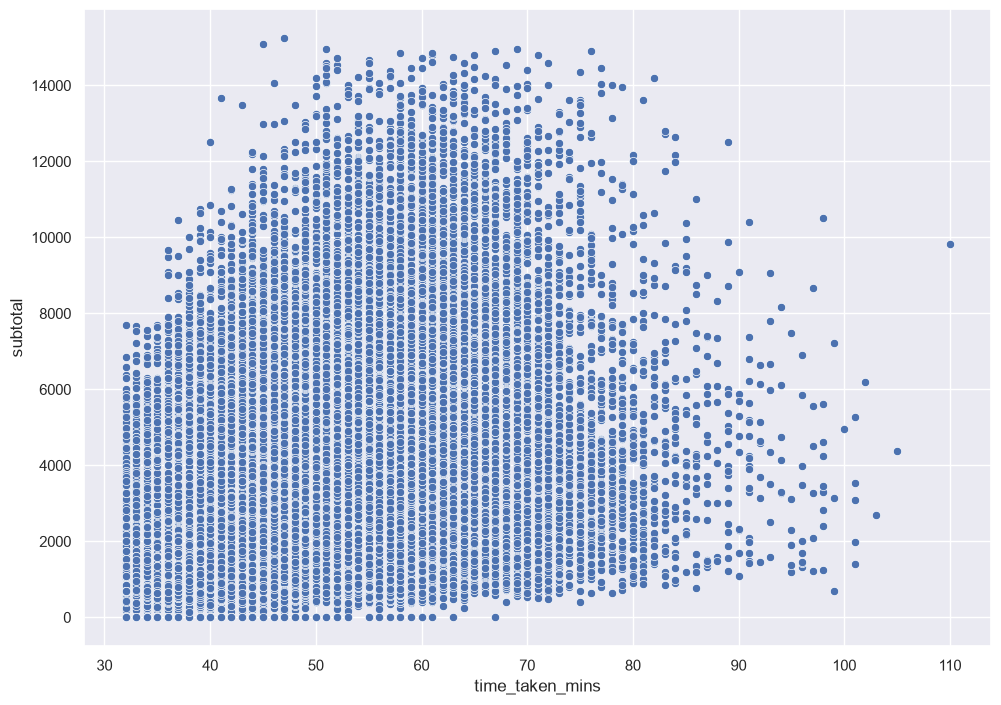

In [21]:
sns.scatterplot(x='time_taken_mins', y='subtotal', data=df)

We can see that after removing outliers our data is looking better

<Axes: xlabel='day', ylabel='count'>

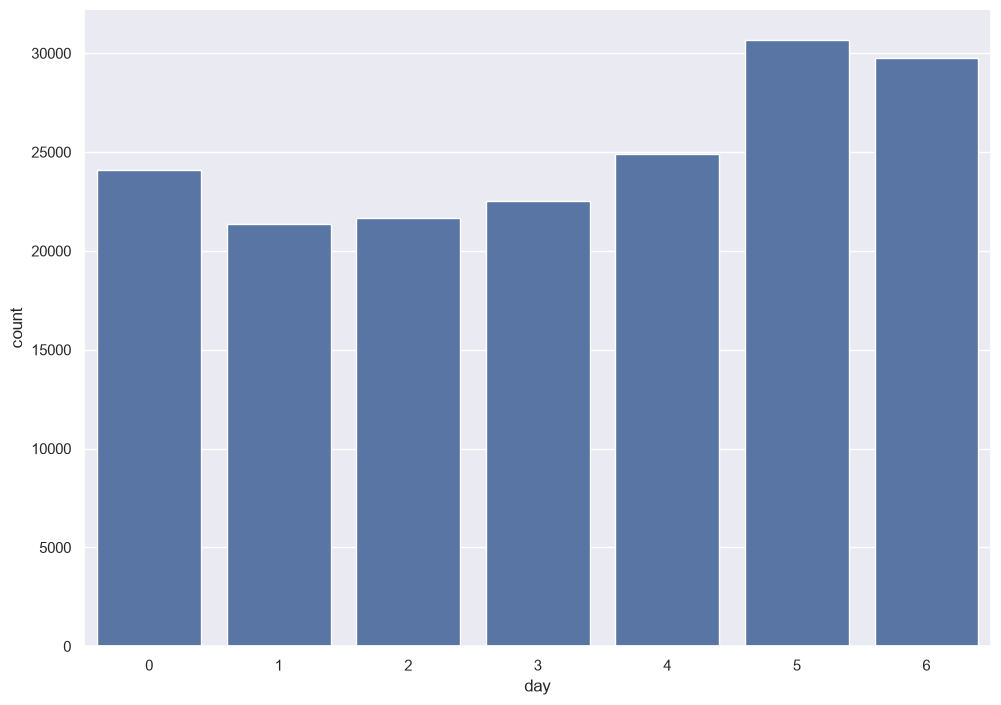

In [22]:
sns.countplot(x=df['day'])

a little more orders on the weekends

<Axes: xlabel='hour', ylabel='count'>

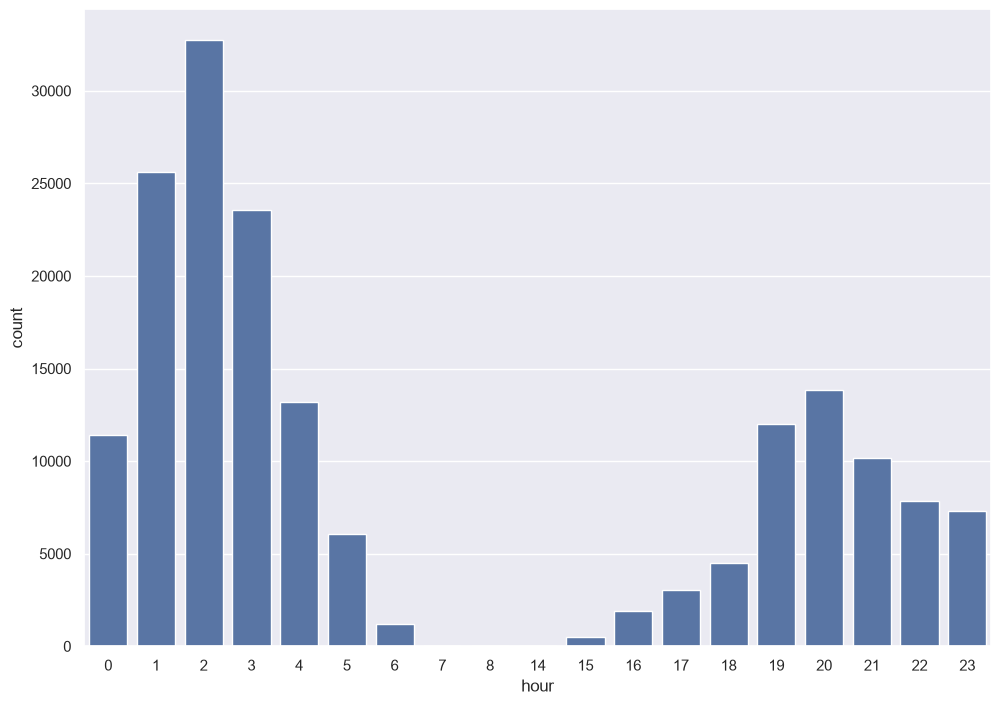

In [23]:
sns.countplot(x=df['hour'])

<Axes: xlabel='hour', ylabel='time_taken_mins'>

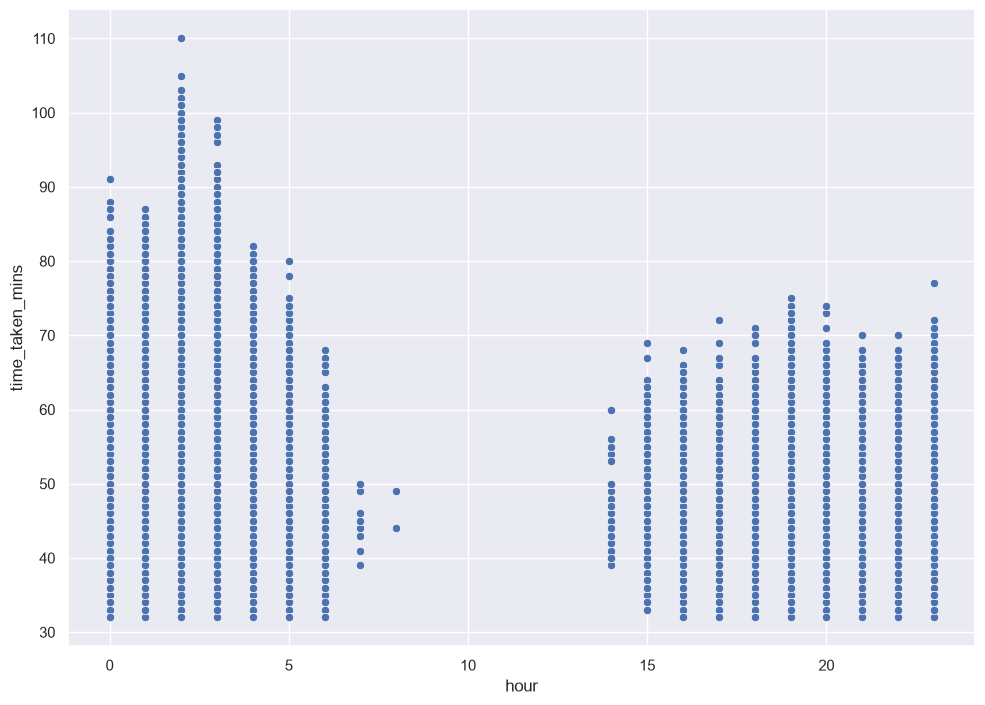

In [24]:
sns.scatterplot(x='hour',y='time_taken_mins', data=df)

## Data Spliting and modeling

In [25]:
y=df['time_taken_mins']
x = df.drop(['time_taken_mins'], axis=1)
df.drop(['time_taken_mins'], axis=1,inplace=True)
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2,  random_state=42)

/var/folders/bn/brz4gkd56s9c6wyvdx2510gm0000gq/T/ipykernel_39429/3245467851.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['time_taken_mins'], axis=1,inplace=True)


In [26]:
x.head()

,market_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_store_to_consumer_driving_duration,hour,day
0,1.0,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,861.0,22,4
1,2.0,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,690.0,21,1
2,2.0,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,289.0,0,0
3,1.0,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,795.0,3,3
4,1.0,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,205.0,2,1


## **Random forest**

In [27]:
regressor = RandomForestRegressor(random_state=42, n_jobs=-1)

regressor.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [28]:
prediction = regressor.predict(X_test)
mse = mean_squared_error(y_test, prediction)
rmse = mse**.5
print("mse : ", mse)
print("rmse : ",rmse)
mae = mean_absolute_error(y_test, prediction)
print('mae:' ,mae)

mse :  3.221100563018005
rmse :  1.7947424781895605
mae: 1.2856870534438412


In [29]:
r2_score(y_test, prediction)

0.9625629273983154

In [30]:
def MAPE(Y_actual,Y_Predicted):
    mape = np.mean(np.abs((Y_actual - Y_Predicted)/Y_actual))*100
    return mape

In [31]:
print("mape : ",MAPE(y_test, prediction))

mape :  2.7695049061879295


Text(0.5, 0, 'Random Forest Feature Importance')

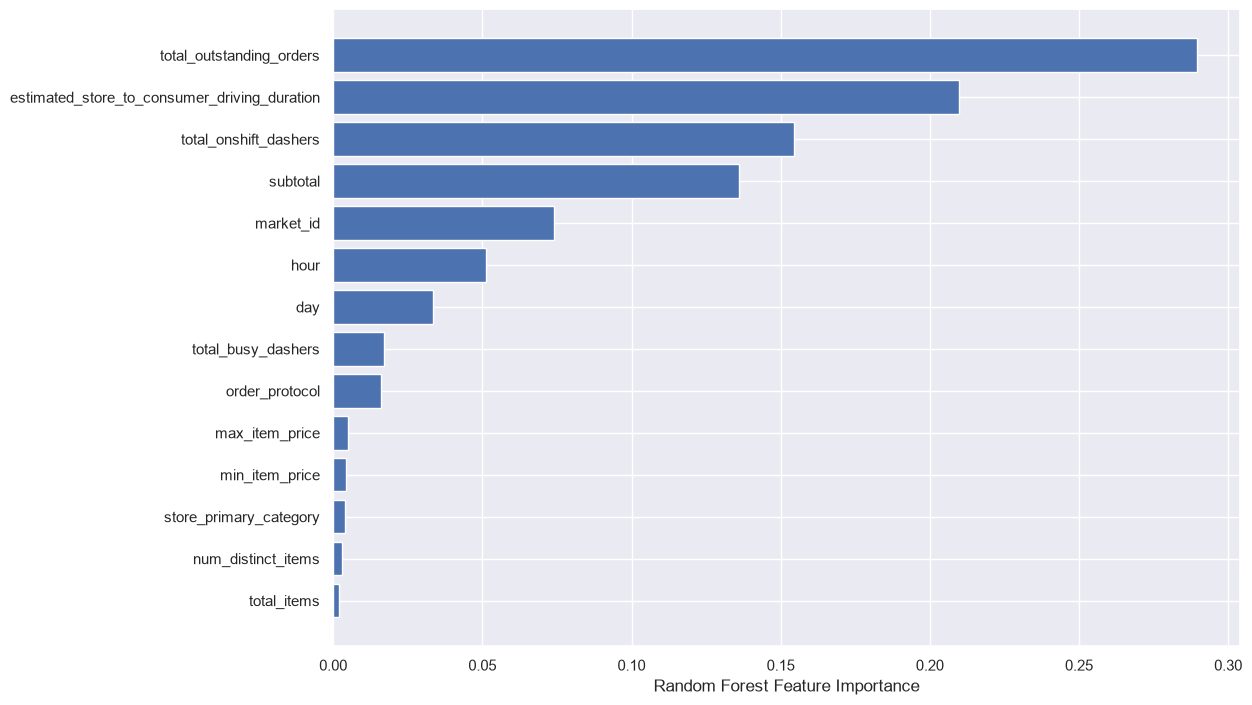

In [32]:
sorted_idx = regressor.feature_importances_.argsort()
plt.barh(df.columns[sorted_idx], regressor.feature_importances_[sorted_idx])
plt.xlabel("Random Forest Feature Importance")

## **Neural networks**

Scalling the data to feed before neural network

In [33]:
from sklearn import preprocessing
scaler = preprocessing.MinMaxScaler()
x_scaled = scaler.fit_transform(x)
X_train, X_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.2,  random_state=42)

We will build a simple neural network to train our regression model, this time in **PyTorch**.
It is a sequential model of fully connected (`nn.Linear`) layers. The first layer has as many nodes as there are input columns (14), and the following layers have 512, 1024 and 256 nodes, which can be changed or experimented with.

The activation for the hidden layers is kept as ReLU because it is a great non linear activation function that works for most cases, we could have used leaky ReLU if we see gradient vanishing.

The last layer has one node because it will give the single result that is our delivery time, and it has **no activation** (a linear output), because the delivery time is a continuous number. In Keras this was `activation='linear'`; in PyTorch a plain `nn.Linear` is already linear.

The Keras layers started with `kernel_initializer='normal'` for the first layer and the default Glorot (Xavier) uniform start for the others, with zero biases. We set the same starting weights here.

In [34]:
n_features = X_train.shape[1]          # 14 input columns

model = nn.Sequential(
    nn.Linear(n_features, 14), nn.ReLU(),
    nn.Linear(14, 512),        nn.ReLU(),
    nn.Linear(512, 1024),      nn.ReLU(),
    nn.Linear(1024, 256),      nn.ReLU(),
    nn.Linear(256, 1),                     # linear output, no activation
).to(device)

# same starting weights as the Keras version
for layer in model:
    if isinstance(layer, nn.Linear):
        nn.init.xavier_uniform_(layer.weight)     # Keras default (glorot_uniform)
        nn.init.zeros_(layer.bias)
nn.init.normal_(model[0].weight, mean=0.0, std=0.05)   # kernel_initializer='normal' on the first layer

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=14, out_features=14, bias=True)
  (1): ReLU()
  (2): Linear(in_features=14, out_features=512, bias=True)
  (3): ReLU()
  (4): Linear(in_features=512, out_features=1024, bias=True)
  (5): ReLU()
  (6): Linear(in_features=1024, out_features=256, bias=True)
  (7): ReLU()
  (8): Linear(in_features=256, out_features=1, bias=True)
)
Trainable parameters: 795859


we use adam optimizer which is extention to classic schostic gradient descent(SGD) algorithm, but handles much of its drawbacks

Stochastic gradient descent maintains a single learning rate (termed alpha) for all weight updates and the learning rate does not change during training.

https://machinelearningmastery.com/adam-optimization-algorithm-for-deep-learning/

Keras has `model.compile` and `model.fit`. PyTorch does not, so we write the training loop ourselves. We pick the loss (`nn.MSELoss`) and the optimizer (`torch.optim.Adam`), and then for every batch we do the same five steps: `zero_grad`, forward pass, loss, `backward`, `step`.

To copy `validation_split=0.2` from Keras, the **last 20% of the training rows** are kept aside as the validation set (they are taken before shuffling). The training loss is the average over the batches of the epoch, and the validation loss is measured at the end of each epoch with `model.eval()` and `torch.no_grad()`.

In [35]:
adam = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()
epochs, batch_size = 30, 512

# validation_split=0.2 -> the last 20% of the training rows
split_at = int(len(X_train) * (1 - 0.2))
X_tr = torch.tensor(X_train[:split_at], dtype=torch.float32).to(device)
y_tr = torch.tensor(y_train.values[:split_at], dtype=torch.float32).reshape(-1, 1).to(device)
X_val = torch.tensor(X_train[split_at:], dtype=torch.float32).to(device)
y_val = torch.tensor(y_train.values[split_at:], dtype=torch.float32).reshape(-1, 1).to(device)
train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)

history = {"loss": [], "mse": [], "mae": [], "val_loss": [], "val_mse": [], "val_mae": []}

for epoch in range(epochs):
    model.train()
    sum_mse, sum_mae, n = 0.0, 0.0, 0
    for xb, yb in train_loader:
        adam.zero_grad()
        pred = model(xb)
        loss = loss_fn(pred, yb)
        loss.backward()
        adam.step()
        sum_mse += loss.item() * len(xb)
        sum_mae += (pred - yb).abs().mean().item() * len(xb)
        n += len(xb)

    model.eval()
    with torch.no_grad():
        vp = model(X_val)
        val_mse = loss_fn(vp, y_val).item()
        val_mae = (vp - y_val).abs().mean().item()

    history["loss"].append(sum_mse / n);  history["mse"].append(sum_mse / n);  history["mae"].append(sum_mae / n)
    history["val_loss"].append(val_mse);  history["val_mse"].append(val_mse);  history["val_mae"].append(val_mae)
    print(f"Epoch {epoch + 1}/{epochs} - loss: {sum_mse / n:.4f} - mae: {sum_mae / n:.4f} - val_loss: {val_mse:.4f} - val_mae: {val_mae:.4f}")

Epoch 1/30 - loss: 194.4386 - mae: 8.7181 - val_loss: 10.5585 - val_mae: 2.4189


Epoch 2/30 - loss: 7.5701 - mae: 2.0153 - val_loss: 6.8408 - val_mae: 1.9053


Epoch 3/30 - loss: 4.6028 - mae: 1.5483 - val_loss: 4.2650 - val_mae: 1.5671


Epoch 4/30 - loss: 2.6226 - mae: 1.2104 - val_loss: 1.6741 - val_mae: 0.9721


Epoch 5/30 - loss: 1.5657 - mae: 0.9623 - val_loss: 1.0531 - val_mae: 0.7874


Epoch 6/30 - loss: 1.3003 - mae: 0.8872 - val_loss: 0.8714 - val_mae: 0.7329


... (20 outputs left out)

Epoch 27/30 - loss: 0.5394 - mae: 0.5933 - val_loss: 1.6670 - val_mae: 1.1802


Epoch 28/30 - loss: 0.6979 - mae: 0.6575 - val_loss: 0.1913 - val_mae: 0.3532


Epoch 29/30 - loss: 0.3946 - mae: 0.4825 - val_loss: 0.2170 - val_mae: 0.3743


Epoch 30/30 - loss: 0.6732 - mae: 0.6107 - val_loss: 0.8806 - val_mae: 0.8336


we plot train and validation loss throughout training

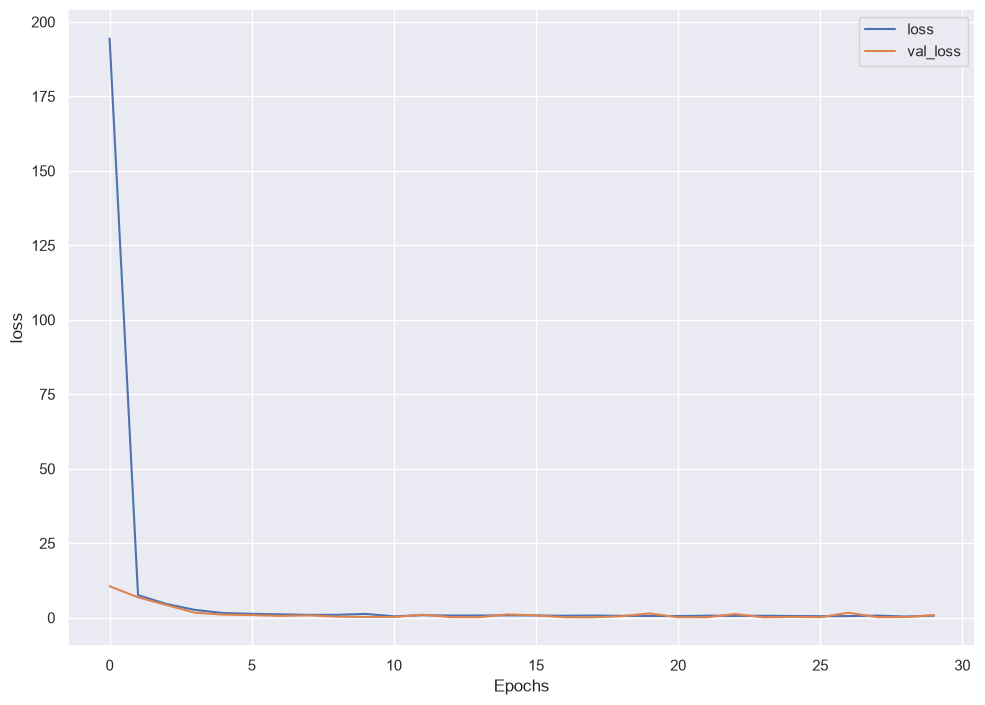

In [36]:
def plot_history(history, key):
  plt.plot(history[key])
  plt.plot(history['val_'+key])
  plt.xlabel("Epochs")
  plt.ylabel(key)
  plt.legend([key, 'val_'+key])
  plt.show()
# Plot the history
plot_history(history, 'loss')

The plot shows the training and validation loss (MSE) over the 30 epochs. Both fall very quickly in the first few epochs (training loss from 194 to 1.6 by epoch 5).

The validation loss is **below** the training loss in 23 of the 30 epochs, so there is no sign of overfitting: the model does not do worse on rows it has not trained on. The training loss is also averaged over the epoch while the weights are still changing, which makes it look a little higher.

One thing to notice is that the validation loss is **not smooth**. It jumps up in some epochs (for example 1.67 at epoch 27) and drops back in the next, and its lowest value (0.127) is at epoch 24, not at the last epoch (0.881). A learning rate of 0.01 is fairly high for Adam, so the steps sometimes overshoot. A smaller learning rate, or keeping the weights of the best epoch, would make the result steadier.

In [37]:
model.eval()
with torch.no_grad():
    z = model(torch.tensor(X_test, dtype=torch.float32).to(device)).cpu().numpy().ravel()

In [38]:
r2_score(y_test, z)

0.9899135185577257

In [39]:
mse = mean_squared_error(y_test, z)
rmse = mse**.5
print("mse : ",mse)
print("rmse : ",rmse)
print("errors for neural net")
mae = mean_absolute_error(y_test, z)
print("mae : ",mae)


mse :  0.8678448605812904
rmse :  0.931581912974533
errors for neural net
mae :  0.8268375211390266


In [40]:
from sklearn.metrics import mean_absolute_percentage_error
print("mape :", mean_absolute_percentage_error(y_test, z) * 100)

mape : 1.8454793880658409


By comparing the results of our neural network model with the random forest model we can see that the neural network is better on every metric (table below), even without tuning it or building a complex architecture: RMSE 0.93 against 1.79 minutes, MAE 0.83 against 1.29, R² 0.990 against 0.963 and MAPE 1.8% against 2.8%.

Two notes on reading these numbers:
- The results come from one run of each model. The saved run of the Keras notebook reached a lower neural network error (RMSE 0.56). The PyTorch run is a little worse, which fits the noisy last epochs seen in the loss plot, and a different random start also changes the result.
- These errors are much lower than in the main solution of this project (RMSE about 4.4 to 4.7 minutes), because this notebook keeps the column `estimated_store_to_consumer_driving_duration` as a feature. The main solution leaves it out, because it is not part of the data dictionary in the problem brief. The two sets of numbers are therefore not comparable.

In [41]:
def report(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return pd.Series({"MSE": mse, "RMSE": mse ** .5, "MAE": mean_absolute_error(y_true, y_pred),
                      "R2": r2_score(y_true, y_pred), "MAPE_percent": MAPE(y_true, y_pred)})

pd.DataFrame({"Random Forest": report(y_test, prediction), "Neural Network (PyTorch)": report(y_test, z)}).round(3)

,Random Forest,Neural Network (PyTorch)
MSE,3.221,0.868
RMSE,1.795,0.932
MAE,1.286,0.827
R2,0.963,0.990
MAPE_percent,2.770,1.845
